# 기능 A KayKit 꼭 넣을 문구 실패 개선 비교 (10/27)

09 "규칙 통과율 개선 비교"에 이어지는 실험이다. 필요한 설정은 이 노트북 안에 모두 넣었다(설정 셀은 09와 같다).

10/27에 (나) 후보 4개 + 지금 규칙(문장 끝에 붙이면 실패)으로 정했다. 이 조합에서 KayKit만 규칙 전부 통과가 0.40이었다(`regen2_by_game.csv`, nai 0.667, x72 0.667). KayKit 실패 9건(15건 중) 중 꼭 넣을 문구 빠짐이 5건이고, 빠진 경우는 모두 store 문장에는 "신규 영웅 로그 추가"가 글자 그대로 있는데 sns 문장에서 "신규 영웅 로그가 등장해", "초록 후드에 숨은 신규 영웅 로그" 처럼 문구를 바꿔 썼다(`regen2_compare.csv`). KayKit의 꼭 넣을 문구만 명사로 끝나는 문구다(nai "…30% 할인"도 명사지만 판촉어, x72 "스팀 찜하기").

후보 세 가지를 같은 입력(KayKit 5장)·같은 seed(0·1·2)로 비교한다. 기준은 09의 `best_of_n4|strict` KayKit 결과(`regen2_compare.csv`)를 그대로 쓴다.

| 후보 | 내용 | 최대 생성 횟수 |
|---|---|---|
| ① 지시문 예시 추가 | 지시문 규칙 1에 명사로 끝나는 꼭 넣을 문구의 좋은 예·나쁜 예(다른 게임, "신규 맵 사막 추가")를 한 줄씩 더한다 | 5번 |
| ② 구체적 재요청 | 후보 4개 중 가장 나은 것이 그래도 실패하면, 그 글과 실패 이유에 "문구를 바꾸지 말고 글자 그대로, 뒤에 조사는 붙여도 됨" 같은 고치는 방법을 더해 샘플링으로 한 번 더 고쳐 쓰게 한다. 실패 항목이 줄었을 때만 바꾼다 | 6번 |
| ③ ① + ② | 둘 다 | 6번 |

- ②는 09의 (가) 재요청(`best_then_fb`, 실패 이유만 보냄)과 같은 구조이고, 실패 이유 아래에 고치는 방법 줄만 더한다.
- 검증·채점은 지금 규칙(strict) 하나로 한다(10/27 결정). 지표는 09와 같다(형식, 꼭 넣을 문구, 문장 안 넣기, 상투 구절, 규칙 전부 통과)이고, 실패 유형별 건수를 따로 센다.
- ①의 지시문은 세 게임 모두에 들어가는 지시문이다. 이 실험은 KayKit만 보므로, ①·③을 채택하면 nai·x72에서 통과율이 떨어지지 않는지 따로 확인해야 한다.
- 기록 (`outputs/local_vlm/`)
  - `kk_must_config.json`: 실험 조건(후보·seed·최대 생성 횟수), 지시문 전문(기준 / ①), 재요청 문구 전문, 검증 규칙 전문, 모델, 패키지 버전, GPU
  - `kk_must_compare.csv`: 건별 기록(최종 문구, 모든 후보 문구, 남은 실패 항목, 생성 횟수, 시간, 최대 VRAM, 모델 로드 시간, 샘플링 설정)
  - `kk_must_runs.csv`: 후보×seed별 시작·종료 시각, 전체 시간, 모델 로드 시간, 최대 VRAM, 건수, 오류 수
  - `kk_must_scored.csv`, `kk_must_summary.csv`, `kk_must_fail_types.csv`, `kk_must_compare.png`, `kk_must_examples.csv`
- 실행 순서: 위에서부터 차례로 실행한다. 중간에 멈춰도 다시 실행하면 끝난 건은 건너뛴다.
- 예상 시간: 후보 3개 × seed 3개 × 5건. 기준 조합의 KayKit 건당 평균 25.0초, 실행 1번(모델 로드 포함)에 약 40초가 더 들었다(`regen2_runs.csv`) → 약 25~30분(추정). 셀 출력과 `kk_must_runs.csv`에 실제 시간을 남긴다.

## 설정 (09와 같음)

In [1]:
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
OUT_DIR = ROOT / 'outputs' / 'local_vlm'
OUT_DIR.mkdir(parents=True, exist_ok=True)

QWEN_REPO = 'Qwen/Qwen3-VL-8B-Instruct'
MAX_NEW_TOKENS = 512

# 기능 A 입력: 02와 같은 표본(게임마다 5장, seed 0)과 같은 지시문
GAMES = {
    'nai': dict(files=sorted((RAW / 'nai/lora_gen').glob('*_screenshot.png')),
                info='냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임'),
    'x72': dict(files=sorted((RAW / 'pixel_0x72/scenes').glob('x72_scene_*.png')), info='픽셀 아트 던전 탐험 게임'),
    'kaykit': dict(files=sorted((RAW / 'kaykit/renders').glob('kk_*.png')), info='로우폴리 3D 판타지 어드벤처 게임'),
}
rng = random.Random(0)
SAMPLES = [(g, p) for g, d in GAMES.items() for p in rng.sample(d['files'], 5)]
TONE = '밝고 친근한 톤'
SYSTEM_A = '너는 1인 인디게임 개발사의 마케팅 카피라이터다.'

# 08 "규칙 적용 지시문"과 같은 판매 포인트·사용자 입력·금지 표현·지시문
# 게임 기본 판매 포인트 (각 게임 데이터 파일에 있는 요소만 사용)
GAME_POINTS = {
    'nai': ['빨간 모자의 검은 고양이 기사가 칼과 방패로 싸우는 횡스크롤 액션', '개 기사·부엉이 마법사·토끼 상인 동료',
            '떠다니는 풀섬, 숲, 선술집, 성문을 넘나드는 스테이지', '동화책 같은 손그림 색감'],
    'x72': ['위에서 내려다보는 16비트 픽셀 던전', '기사·엘프·마법사·드워프 중 골라 플레이',
            '오크·해골·좀비·네크로맨서 등 몬스터', '금화·물약·보물상자(미믹 포함) 수집'],
    'kaykit': ['바바리안·기사·마법사·로그 등 5명의 로우폴리 영웅', '한손·양손 무기, 석궁, 지팡이를 쓰는 전투',
               '회피·막기·연속 공격 액션'],
}
# 사용자 입력 예시 (게임마다 1개). 냥기사는 판촉 표현이 사용자 입력에 있을 때 허용되는지 보려고 할인 문구를 넣음
USER_POINTS = {
    'nai': dict(points='11월 업데이트로 신규 동료 추가', must='11월 업데이트 기념 30% 할인'),
    'x72': dict(points='4인 로컬 협동 플레이 지원', must='스팀 찜하기'),
    'kaykit': dict(points='영웅마다 다른 전용 스킬', must='신규 영웅 로그 추가'),
}
BANNED_PROMO = ['할인', '특가', '무료', '이벤트', '출시', '사전예약', '선물']
BANNED_CLICHE = ['모험을 떠나', '떠나보세요', '떠나볼까요', '함께 떠나', '기다리고 있어요', '귀여운 친구들']

INSTRUCTION_A2 = '''게임 정보: {info}
{user_block}
게임 기본 판매 포인트 (사용자 입력이 없거나 부족할 때만 참고):
{points}
요청 사항: {tone}

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
규칙
1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: {cliche}
4. 이미지에 보이는 구체적인 요소(색, 사물, 장소, 행동)를 1개 이상 넣어줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"store": ["문장1", "문장2"], "sns": "문장"}}'''


# 08 "꼭 넣을 문구 처리 방식 비교"와 같은 검증 규칙·지시문 보강·입력
MUST_CSV = OUT_DIR / 'must_phrase_compare.csv'
# Instructor 문서 reask 예시값
MAX_RETRY = 2

VALIDATOR = r"""
import json, re


def parse_json(text):
    m = re.search(r'\{.*\}', str(text), re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    return d if isinstance(d, dict) else None


def n_sentences(s):
    # 글자가 없는 조각(문장 끝 이모지·기호)은 문장으로 세지 않음 (02와 같은 기준)
    return len([x for x in re.split(r'(?<=[.!?…])\s+', s.strip()) if re.search(r'[가-힣A-Za-z一-鿿]', x)])


def integrated(sns, must):
    if must not in sns or n_sentences(sns) != 1:
        return False
    if len(re.findall(r'[가-힣]', sns.replace(must, ' '))) < 8:
        return False
    p = re.escape(must)
    if re.search(r'[.!?…,:;~\-—]\s*' + p + r'\s*[.!?…~]*\s*$', sns) or re.match(r'^\s*' + p + r'\s*[.!?…,:;~\-—]', sns):
        return False
    return True


def check(text, must, allowed, banned_promo, banned_cliche, need_must):
    d = parse_json(text)
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return ['JSON 형식이 아니다. {"store": ["문장1", "문장2"], "sns": "문장"} 형식으로만 써야 한다.']
    store = [str(x) for x in d['store']]
    sns = d['sns']
    probs = []
    n_store, n_sns = sum(n_sentences(x) for x in store), n_sentences(sns)
    if n_store != 2:
        probs.append(f'store는 정확히 2문장이어야 하는데 {n_store}문장이다.')
    if n_sns != 1:
        probs.append(f'sns는 정확히 1문장이어야 하는데 {n_sns}문장이다.')
    if need_must:
        if must not in sns:
            probs.append(f'꼭 넣을 문구 "{must}"가 sns 문장에 글자 그대로 들어 있지 않다.')
        elif not integrated(sns, must):
            probs.append(f'꼭 넣을 문구 "{must}"가 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.')
    body = ' '.join(store) + ' ' + sns
    words = [w for w in banned_promo if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    if words or nums:
        probs.append(f'사용자 입력에 없는 판촉 표현을 썼다: {", ".join(words + nums)}')
    cl = [c for c in banned_cliche if c in body]
    if cl:
        probs.append(f'쓰지 말라는 표현을 썼다: {", ".join(cl)}')
    return probs
"""
exec(VALIDATOR)

RULE1 = '1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.'
assert INSTRUCTION_A2.count(RULE1) == 1
INSTRUCTION_A3 = INSTRUCTION_A2.replace(RULE1, '\n'.join([
    RULE1,
    '   "꼭 넣을 문구"는 sns 문장 안에 문장의 일부로 넣고, 문장 앞이나 뒤에 따로 붙이지 마.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "데모 플레이 가능"): "눈 덮인 마을의 여우 기사 이야기, 데모 플레이 가능 소식을 지금 확인해 보세요."',
    '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"']))


def must_task(g, p, method):
    u = USER_POINTS[g]
    if method == 'pin':
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']}", INSTRUCTION_A2
    else:
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\"", INSTRUCTION_A3
    prompt = instr.format(info=GAMES[g]['info'], user_block=ub, points='\n'.join('- ' + x for x in GAME_POINTS[g]),
                          tone=TONE, cliche=', '.join(BANNED_CLICHE))
    return dict(method=method, item=p.name, game=g, image=str(p.resolve()), system=SYSTEM_A, prompt=prompt,
                must=u['must'], allowed=' '.join(u.values()), need_must=(method == 'retry'))


MUST_TASKS = [must_task(g, p, m) for m in ['retry', 'pin'] for g, p in SAMPLES]


# 08 "비교 지표와 그래프"와 같은 채점 함수
def score_must(text, g, method):
    d = parse_json(text)
    u = USER_POINTS[g]
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return dict(json_ok=False, format_ok=False, must_kept=method == 'pin', integrated=False, promo_violation=np.nan, cliche=np.nan)
    store, sns = [str(x) for x in d['store']], d['sns']
    body = ' '.join(store) + ' ' + sns
    allowed = ' '.join(u.values())
    words = [w for w in BANNED_PROMO if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    return dict(json_ok=True,
                format_ok=sum(n_sentences(x) for x in store) == 2 and n_sentences(sns) == 1,
                must_kept=True if method == 'pin' else u['must'] in sns,
                integrated=False if method == 'pin' else integrated(sns, u['must']),
                promo_violation=bool(words or nums), cliche=any(c in body for c in BANNED_CLICHE))

print(len(MUST_TASKS), 'tasks |', sum(t['method'] == 'retry' for t in MUST_TASKS), 'retry tasks')

30 tasks | 15 retry tasks


## 후보 지시문·재요청 문구

In [2]:
KK_CSV = OUT_DIR / 'kk_must_compare.csv'
KK_RUNS_CSV = OUT_DIR / 'kk_must_runs.csv'
KK_CONFIG = OUT_DIR / 'kk_must_config.json'
REGEN2_CSV = OUT_DIR / 'regen2_compare.csv'
BASE_LABEL = 'best_of_n4|strict'
KK_SEEDS = [0, 1, 2]
N_CAND = 4

# ① 지시문 예시 추가: 09 지시문(INSTRUCTION_A3)의 나쁜 예 줄 다음에 명사로 끝나는 문구의 예를 더함
BAD_LINE = '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"'
assert INSTRUCTION_A3.count(BAD_LINE) == 1
INSTRUCTION_EX = INSTRUCTION_A3.replace(BAD_LINE, '\n'.join([
    BAD_LINE,
    '   꼭 넣을 문구가 명사로 끝나면 단어를 바꾸지 말고 뒤에 조사를 붙여 넣어줘.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "신규 맵 사막 추가"): "모래바람이 부는 협곡을 달리는 기사단, 신규 맵 사막 추가로 더 넓어진 세계를 만나 보세요."',
    '   나쁜 예: "신규 맵으로 사막이 추가되어 모래바람 협곡을 달릴 수 있어요." (문구를 바꿔 씀)']))

# ② 구체적 재요청: 09 (가) 재요청 문구 + 실패 이유별 고치는 방법
FB_HEAD = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n'
FB_HINTS = {
    'missing': '- 고치는 방법: "{must}"의 단어를 바꾸거나 나누거나 순서를 바꾸지 말고 글자 그대로 sns 문장에 넣어. 바로 뒤에 조사를 붙여도 된다 (예: "{must}로", "{must} 소식과 함께").',
    'attached': '- 고치는 방법: "{must}"를 문장 끝이나 앞에 쉼표로 붙이지 말고 문장 가운데에 넣어 (예: "…, {must}로 더 다채로워진 전투를 만나 보세요.").',
}
# 실패 이유 문장(VALIDATOR check)에서 어떤 고치는 방법을 붙일지 고르는 표시
FB_KEYS = {'missing': '글자 그대로 들어 있지 않다', 'attached': '따로 붙어 있다'}

KK_TASKS_BASE = [t for t in MUST_TASKS if t['method'] == 'retry' and t['game'] == 'kaykit']


def with_prompt(t, instr):
    u = USER_POINTS[t['game']]
    ub = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\""
    prompt = instr.format(info=GAMES[t['game']]['info'], user_block=ub,
                          points='\n'.join('- ' + x for x in GAME_POINTS[t['game']]), tone=TONE,
                          cliche=', '.join(BANNED_CLICHE))
    return dict(t, prompt=prompt)


# 지시문을 바꾸지 않은 경우 09와 같은 프롬프트인지 확인
assert all(with_prompt(t, INSTRUCTION_A3)['prompt'] == t['prompt'] for t in KK_TASKS_BASE)

# (이름, 지시문, 구체적 재요청 여부)
KK_RUNS = [('n4+example', INSTRUCTION_EX, False), ('n4+fb_specific', INSTRUCTION_A3, True),
           ('n4+example+fb_specific', INSTRUCTION_EX, True)]
KK_TASKS = {label: [with_prompt(t, instr) for t in KK_TASKS_BASE] for label, instr, _ in KK_RUNS}
print('KayKit', len(KK_TASKS_BASE), '건:', [t['item'] for t in KK_TASKS_BASE], '| 꼭 넣을 문구:', USER_POINTS['kaykit']['must'])
print('\n[① 지시문에서 더한 부분]')
print(INSTRUCTION_EX.split(BAD_LINE)[1].split('2. ')[0])
print('[② 재요청 예시: 문구가 빠진 경우]')
print(FB_HEAD + f'- 꼭 넣을 문구 "{USER_POINTS["kaykit"]["must"]}"가 sns 문장에 글자 그대로 들어 있지 않다.\n'
      + FB_HINTS['missing'].format(must=USER_POINTS['kaykit']['must']))


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


import importlib.metadata
import platform

# 보고서용 실험 설정 기록
config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), model=QWEN_REPO, max_new_tokens=MAX_NEW_TOKENS, seeds=KK_SEEDS, n_cand=N_CAND,
    baseline=f'{BASE_LABEL} KayKit = 09 "규칙 통과율 개선 비교" (regen2_compare.csv)',
    runs=[dict(label=label, instruction='example' if instr is INSTRUCTION_EX else '09 INSTRUCTION_A3', fb_specific=fb,
               max_generations=1 + N_CAND + (1 if fb else 0)) for label, instr, fb in KK_RUNS],
    tasks=[dict(item=t['item'], game=t['game'], must=t['must'], allowed=t['allowed']) for t in KK_TASKS_BASE],
    system_prompt=SYSTEM_A, prompt_base=KK_TASKS_BASE[0]['prompt'], prompt_example=KK_TASKS['n4+example'][0]['prompt'],
    fb_head=FB_HEAD, fb_hints=FB_HINTS, fb_keys=FB_KEYS, banned_promo=BANNED_PROMO, banned_cliche=BANNED_CLICHE,
    validator_strict=VALIDATOR,
    versions={p: pkg_version(p) for p in ['torch', 'transformers', 'accelerate', 'pillow', 'pandas', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
KK_CONFIG.write_text(json.dumps(config, ensure_ascii=False, indent=1), encoding='utf-8')
print('\n설정 기록:', KK_CONFIG.name, '| GPU:', config['gpu'], '| transformers', config['versions']['transformers'])

KayKit 5 건: ['kk_0223.png', 'kk_0516.png', 'kk_0142.png', 'kk_0288.png', 'kk_0143.png'] | 꼭 넣을 문구: 신규 영웅 로그 추가

[① 지시문에서 더한 부분]

   꼭 넣을 문구가 명사로 끝나면 단어를 바꾸지 말고 뒤에 조사를 붙여 넣어줘.
   좋은 예 (다른 게임, 꼭 넣을 문구 "신규 맵 사막 추가"): "모래바람이 부는 협곡을 달리는 기사단, 신규 맵 사막 추가로 더 넓어진 세계를 만나 보세요."
   나쁜 예: "신규 맵으로 사막이 추가되어 모래바람 협곡을 달릴 수 있어요." (문구를 바꿔 씀)

[② 재요청 예시: 문구가 빠진 경우]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.
- 꼭 넣을 문구 "신규 영웅 로그 추가"가 sns 문장에 글자 그대로 들어 있지 않다.
- 고치는 방법: "신규 영웅 로그 추가"의 단어를 바꾸거나 나누거나 순서를 바꾸지 말고 글자 그대로 sns 문장에 넣어. 바로 뒤에 조사를 붙여도 된다 (예: "신규 영웅 로그 추가로", "신규 영웅 로그 추가 소식과 함께").

설정 기록: kk_must_config.json | GPU: NVIDIA GeForce RTX 3090, 24576 MiB, 610.88 | transformers 5.20.1


## 생성 (후보 3개 × seed 3개)

In [3]:
CHILD_KK = r"""
import csv, json, os, sys, time
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
FIELDS = ['method', 'seed', 'item', 'game', 'n_gen', 'sec_total', 'peak_vram_gb', 'load_sec', 'text', 'texts_all',
          'problems', 'fb_sent', 'identical_repeats', 'gen_cfg', 'error']


def write(rec):
    new = not os.path.exists(a['out'])
    with open(a['out'], 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


t0 = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 1)
gc = model.generation_config
GEN_CFG = json.dumps(dict(temperature=gc.temperature, top_p=gc.top_p, top_k=gc.top_k,
                          repetition_penalty=getattr(gc, 'repetition_penalty', None)))
print('LOADED', load_sec, 's | sampling defaults', GEN_CFG, flush=True)


def gen(messages, sample, n=1):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)


def probs_of(text, t):
    return check(text, t['must'], t['allowed'], a['banned_promo'], a['banned_cliche'], True)


def feedback(probs, must):
    # 실패 이유 줄 아래에, 해당하는 고치는 방법 줄을 붙임
    out = []
    for p in probs:
        out.append('- ' + p)
        for key, mark in a['fb_keys'].items():
            if mark in p:
                out.append(a['fb_hints'][key].format(must=must))
    return a['fb_head'] + '\n'.join(out)


for t in a['tasks']:
    rec = dict(method=a['label'], seed=a['seed'], item=t['item'], game=t['game'], load_sec=load_sec, gen_cfg=GEN_CFG)
    try:
        torch.manual_seed(a['seed'])
        messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                    {'role': 'user', 'content': [{'type': 'image', 'image': Image.open(t['image']).convert('RGB')},
                                                 {'type': 'text', 'text': t['prompt']}]}]
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        texts = gen(messages, sample=False)
        final, probs = texts[0], probs_of(texts[0], t)
        fb_sent = ''
        if probs:
            # (나): 같은 입력으로 샘플링 후보 n개 → 실패 항목이 가장 적은 후보
            cands = gen(messages, sample=True, n=a['n_cand'])
            texts += cands
            n_bad, _, best = min((len(probs_of(c, t)), i, c) for i, c in enumerate(cands))
            if n_bad < len(probs):
                final, probs = best, probs_of(best, t)
            if probs and a['fb_specific']:
                # ② 구체적 재요청: 가장 나은 글 + 실패 이유 + 고치는 방법
                fb_sent = feedback(probs, t['must'])
                m2 = messages + [{'role': 'assistant', 'content': [{'type': 'text', 'text': final}]},
                                 {'role': 'user', 'content': [{'type': 'text', 'text': fb_sent}]}]
                fix = gen(m2, sample=True)[0]
                texts.append(fix)
                fp = probs_of(fix, t)
                if len(fp) < len(probs):
                    final, probs = fix, fp
        rec.update(n_gen=len(texts), sec_total=round(time.perf_counter() - t1, 2),
                   peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2), text=final,
                   texts_all=json.dumps(texts, ensure_ascii=False), problems=json.dumps(probs, ensure_ascii=False),
                   fb_sent=fb_sent, identical_repeats=sum(texts[i] == texts[i - 1] for i in range(1, len(texts))))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    write(rec)
    print(a['label'], a['seed'], t['item'], rec.get('n_gen'), rec.get('sec_total'), 's', rec.get('error', '')[:120], flush=True)
"""

done = set()
if KK_CSV.exists():
    _r = pd.read_csv(KK_CSV, keep_default_na=False, dtype=str)
    _r = _r[_r.error == '']
    done = set(zip(_r.method, _r.seed.astype(int), _r['item']))
for label, instr, fb in KK_RUNS:
    for seed in KK_SEEDS:
        todo = [t for t in KK_TASKS[label] if (label, seed, t['item']) not in done]
        if not todo:
            print(label, seed, '이미 완료 → 건너뜀')
            continue
        t_run = time.perf_counter()
        arg = json.dumps(dict(repo=QWEN_REPO, label=label, seed=seed, n_cand=N_CAND, fb_specific=fb,
                              max_new_tokens=MAX_NEW_TOKENS, validator=VALIDATOR, banned_promo=BANNED_PROMO,
                              banned_cliche=BANNED_CLICHE, fb_head=FB_HEAD, fb_hints=FB_HINTS, fb_keys=FB_KEYS,
                              out=str(KK_CSV.resolve()), tasks=todo))
        p = subprocess.run([sys.executable, '-c', CHILD_KK], input=arg, capture_output=True, text=True, encoding='utf-8',
                           errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
        sec = round(time.perf_counter() - t_run, 1)
        print(p.stdout[-800:])
        if p.returncode != 0:
            print(p.stderr[-2000:])
        # 보고서용 실행 기록: 후보×seed마다 시각·시간·VRAM·건수·오류
        _w = pd.read_csv(KK_CSV, keep_default_na=False, dtype=str) if KK_CSV.exists() else pd.DataFrame()
        _w = _w[(_w.method == label) & (_w.seed == str(seed))] if len(_w) else _w
        run_rec = dict(label=label, fb_specific=fb, instruction='example' if instr is INSTRUCTION_EX else 'A3', seed=seed,
                       started=time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(time.time() - sec)),
                       ended=time.strftime('%Y-%m-%d %H:%M:%S'), sec_total=sec, returncode=p.returncode,
                       n_tasks=len(todo), n_rows=len(_w), n_errors=int((_w.error != '').sum()) if len(_w) else 0,
                       load_sec=float(_w.load_sec.iloc[0]) if len(_w) and _w.load_sec.iloc[0] else None,
                       peak_vram_gb=pd.to_numeric(_w.peak_vram_gb, errors='coerce').max() if len(_w) else None,
                       stderr_tail=p.stderr[-300:] if p.returncode != 0 else '')
        pd.DataFrame([run_rec]).to_csv(KK_RUNS_CSV, mode='a', header=not KK_RUNS_CSV.exists(), index=False,
                                       encoding='utf-8-sig')
        print(f'{label} seed {seed}: {sec}초 (모델 로드 포함), 오류 {run_rec["n_errors"]}건', flush=True)

LOADED 23.7 s | sampling defaults {"temperature": 0.7, "top_p": 0.8, "top_k": 20, "repetition_penalty": 1.0}
n4+example 0 kk_0223.png 1 12.37 s 
n4+example 0 kk_0516.png 5 23.76 s 
n4+example 0 kk_0142.png 5 28.33 s 
n4+example 0 kk_0288.png 5 30.47 s 
n4+example 0 kk_0143.png 1 12.03 s 

n4+example seed 0: 155.3초 (모델 로드 포함), 오류 0건
LOADED 27.5 s | sampling defaults {"temperature": 0.7, "top_p": 0.8, "top_k": 20, "repetition_penalty": 1.0}
n4+example 1 kk_0223.png 1 13.33 s 
n4+example 1 kk_0516.png 5 26.95 s 
n4+example 1 kk_0142.png 5 25.28 s 
n4+example 1 kk_0288.png 5 26.51 s 
n4+example 1 kk_0143.png 1 10.87 s 

n4+example seed 1: 155.1초 (모델 로드 포함), 오류 0건
LOADED 21.6 s | sampling defaults {"temperature": 0.7, "top_p": 0.8, "top_k": 20, "repetition_penalty": 1.0}
n4+example 2 kk_0223.png 1 14.16 s 
n4+example 2 kk_0516.png 5 29.55 s 
n4+example 2 kk_0142.png 5 27.09 s 
n4+example 2 kk_0288.png 5 31.4 s 
n4+example 2 kk_0143.png 1 12.4 s 

n4+example seed 2: 163.1초 (모델 로드 포함), 오류 0건


## 지표와 그래프

후보별 건수: {'best_of_n4|strict': 15, 'n4+example': 15, 'n4+example+fb_specific': 15, 'n4+fb_specific': 15}


format_ok        must_kept        integrated         \
                            mean    std      mean    std       mean    std   
method                                                                       
best_of_n4|strict          0.800  0.200     0.667  0.115      0.533  0.115   
n4+example                 1.000  0.000     0.933  0.115      0.933  0.115   
n4+fb_specific             0.867  0.115     1.000  0.000      0.867  0.115   
n4+example+fb_specific     1.000  0.000     1.000  0.000      1.000  0.000   

                       cliche        all_rules         n_gen            sec  \
                         mean    std      mean    std   mean    std    mean   
method                                                                        
best_of_n4|strict       0.133  0.115     0.400  0.000  5.000  0.000  25.027   
n4+example              0.000  0.000     0.933  0.115  3.400  0.000  21.633   
n4+fb_specific          0.133  0.115     0.733  0.115  5.600  0.000  39.881   
n4+example+fb_specific  0.000  0.000     1.000  0.000  3.467  0.115  26.039   

                              fb_used         
                          std    mean    std  
method                                        
best_of_n4|strict       1.843   0.000  0.000  
n4+example              1.185   0.000  0.000  
n4+fb_specific          2.846   0.600  0.000  
n4+example+fb_specific  1.733   0.067  0.115

실패 유형별 건수 (seed 3개 합)


,fail_format,fail_missing,fail_attached,fail_promo,fail_cliche,n_failed,n
method,,,,,,,
best_of_n4|strict,3,5,2,0,2,9,15
n4+example,0,1,0,0,0,1,15
n4+fb_specific,2,0,2,0,2,4,15
n4+example+fb_specific,0,0,0,0,0,0,15


후보별 실행 기록 (kk_must_runs.csv)


,label,fb_specific,instruction,seed,started,ended,sec_total,returncode,n_tasks,n_rows,n_errors,load_sec,peak_vram_gb,stderr_tail
0,n4+example,False,example,0,2026-10-27 13:40:32,2026-10-27 13:43:07,155.3,0,5,5,0,23.7,18.22,
1,n4+example,False,example,1,2026-10-27 13:43:07,2026-10-27 13:45:43,155.1,0,5,5,0,27.5,18.22,
2,n4+example,False,example,2,2026-10-27 13:45:43,2026-10-27 13:48:26,163.1,0,5,5,0,21.6,18.22,
3,n4+fb_specific,True,A3,0,2026-10-27 13:48:26,2026-10-27 13:52:14,228.8,0,5,5,0,20.0,18.09,
4,n4+fb_specific,True,A3,1,2026-10-27 13:52:14,2026-10-27 13:56:34,259.5,0,5,5,0,20.9,18.09,
5,n4+fb_specific,True,A3,2,2026-10-27 13:56:34,2026-10-27 14:00:56,262.3,0,5,5,0,27.2,18.09,
6,n4+example+fb_specific,True,example,0,2026-10-27 14:00:56,2026-10-27 14:04:08,192.1,0,5,5,0,30.7,18.22,
7,n4+example+fb_specific,True,example,1,2026-10-27 14:04:08,2026-10-27 14:07:26,197.4,0,5,5,0,27.2,18.22,
8,n4+example+fb_specific,True,example,2,2026-10-27 14:07:26,2026-10-27 14:10:27,180.9,0,5,5,0,27.1,18.22,


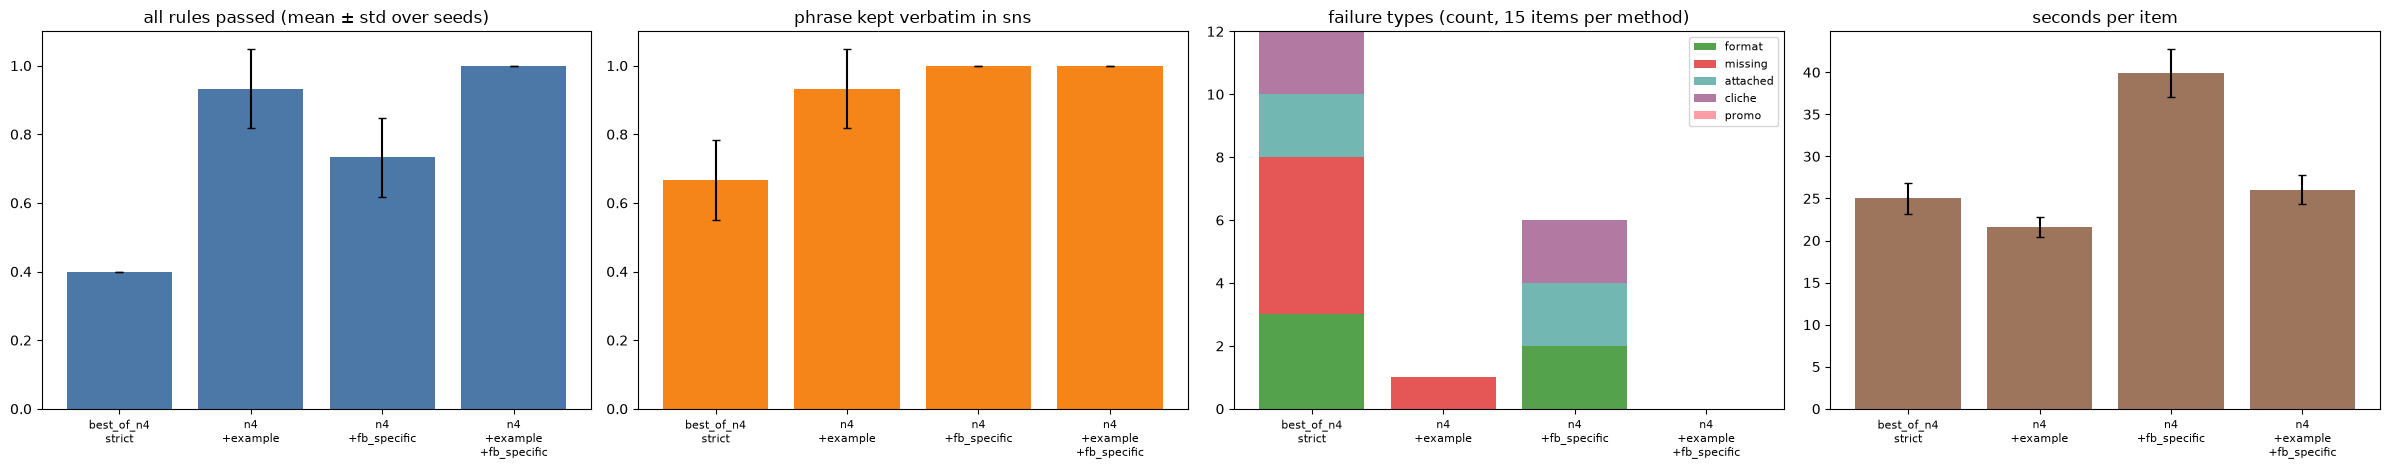

In [4]:
base = pd.read_csv(REGEN2_CSV, keep_default_na=False)
base = base[(base.error == '') & (base.method == BASE_LABEL) & (base.game == 'kaykit')]
new = pd.read_csv(KK_CSV, keep_default_na=False)
new = new[new.error == '']
kk = pd.concat([base.drop_duplicates(['method', 'seed', 'item'], keep='last'),
                new.drop_duplicates(['method', 'seed', 'item'], keep='last')], ignore_index=True)
# 기준(09) 기록에는 재요청 열이 없음
kk['fb_sent'] = kk['fb_sent'].fillna('') if 'fb_sent' in kk else ''
rows = []
for _, r in kk.iterrows():
    s = score_must(r.text, r.game, 'retry')
    rows.append(dict(method=r.method, seed=int(r.seed), item=r['item'], n_gen=int(r.n_gen), sec=float(r.sec_total),
                     fb_used=bool(r.get('fb_sent', '')), text=r.text, **s))
kks = pd.DataFrame(rows)
kks['all_rules'] = kks.format_ok & kks.must_kept & kks.integrated & (kks.promo_violation == False) & (kks.cliche == False)
# 실패 유형 (한 건이 여러 유형에 걸릴 수 있음). 문장 안 넣기는 문구가 들어 있는 경우만 센다
kks['fail_format'] = ~kks.format_ok
kks['fail_missing'] = ~kks.must_kept
kks['fail_attached'] = kks.must_kept & ~kks.integrated
kks['fail_promo'] = kks.promo_violation == True
kks['fail_cliche'] = kks.cliche == True
KK_METHODS = [BASE_LABEL] + [label for label, _, _ in KK_RUNS]
methods = [m for m in KK_METHODS if m in set(kks.method)]

per_seed = kks.groupby(['method', 'seed']).agg(
    format_ok=('format_ok', 'mean'), must_kept=('must_kept', 'mean'), integrated=('integrated', 'mean'),
    cliche=('cliche', 'mean'), all_rules=('all_rules', 'mean'), n_gen=('n_gen', 'mean'), sec=('sec', 'mean'),
    fb_used=('fb_used', 'mean'))
summ = per_seed.groupby('method').agg(['mean', 'std']).reindex(methods)
fails = kks.groupby('method')[['fail_format', 'fail_missing', 'fail_attached', 'fail_promo', 'fail_cliche']].sum()
fails['n_failed'] = (~kks.all_rules).groupby(kks.method).sum()
fails['n'] = kks.groupby('method').size()
fails = fails.reindex(methods)
kks.to_csv(OUT_DIR / 'kk_must_scored.csv', index=False, encoding='utf-8-sig')
summ.to_csv(OUT_DIR / 'kk_must_summary.csv', encoding='utf-8-sig')
fails.to_csv(OUT_DIR / 'kk_must_fail_types.csv', encoding='utf-8-sig')
print('후보별 건수:', kks.groupby('method').size().to_dict())
display(summ.round(3))
print('실패 유형별 건수 (seed 3개 합)')
display(fails)
if KK_RUNS_CSV.exists():
    print('후보별 실행 기록 (kk_must_runs.csv)')
    display(pd.read_csv(KK_RUNS_CSV, keep_default_na=False))

fig, axes = plt.subplots(1, 4, figsize=(24, 4.8))
x = np.arange(len(methods))
names = [m.replace('|', '\n').replace('+', '\n+') for m in methods]
for ax, col, title, color in [(axes[0], 'all_rules', 'all rules passed (mean ± std over seeds)', '#4C78A8'),
                              (axes[1], 'must_kept', 'phrase kept verbatim in sns', '#F58518')]:
    ax.bar(x, summ[(col, 'mean')], yerr=summ[(col, 'std')].fillna(0), capsize=3, color=color)
    ax.set_ylim(0, 1.1)
    ax.set_title(title)
ft = fails[['fail_format', 'fail_missing', 'fail_attached', 'fail_cliche', 'fail_promo']]
bottom = np.zeros(len(methods))
for c, color in zip(ft.columns, ['#54A24B', '#E45756', '#72B7B2', '#B279A2', '#FF9DA6']):
    axes[2].bar(x, ft[c], bottom=bottom, color=color, label=c.replace('fail_', ''))
    bottom += ft[c].values
axes[2].set_title(f'failure types (count, {int(fails.n.iloc[0])} items per method)')
axes[2].legend(fontsize=8)
axes[3].bar(x, summ[('sec', 'mean')], yerr=summ[('sec', 'std')].fillna(0), capsize=3, color='#9D755D')
axes[3].set_title('seconds per item')
for ax in axes:
    ax.set_xticks(x, names, fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / 'kk_must_compare.png', dpi=90)
plt.show()

## 이미지·seed별 sns 문장

In [5]:
pd.set_option('display.max_colwidth', 400)
# 보고서용: 이미지·seed별로 후보마다 최종 sns 문장과 통과 여부를 나란히 저장
kks['sns'] = kks.text.map(lambda t: (parse_json(t) or {}).get('sns', ''))
ex = kks.pivot_table(index=['item', 'seed'], columns='method', values='sns', aggfunc='first').reindex(columns=methods)
ok = kks.pivot_table(index=['item', 'seed'], columns='method', values='all_rules', aggfunc='first').reindex(columns=methods)
ex_all = ex.join(ok, rsuffix=' 통과')
ex_all.to_csv(OUT_DIR / 'kk_must_examples.csv', encoding='utf-8-sig')
print('꼭 넣을 문구:', USER_POINTS['kaykit']['must'])
display(ex_all.xs(0, level='seed'))
# 구체적 재요청이 실제로 나간 건의 재요청 문장 예시
sent = new[new.fb_sent != ''][['method', 'seed', 'item', 'fb_sent']].head(3)
for _, r in sent.iterrows():
    print(f'\n[{r.method} seed {r.seed} {r["item"]}]\n{r.fb_sent}')

꼭 넣을 문구: 신규 영웅 로그 추가


method,best_of_n4|strict,n4+example,n4+fb_specific,n4+example+fb_specific,best_of_n4|strict 통과,n4+example 통과,n4+fb_specific 통과,n4+example+fb_specific 통과
item,,,,,,,,
kk_0142.png,"붉은 망토 휘날리며 돌진하는 로그, 신규 영웅 로그 추가로 전투의 재미가 한층 더해졌어요!","구름 위를 날아다니는 로그의 붉은 망토, 신규 영웅 로그 추가로 새로운 전투를 시작해 보세요.","붉은 망토 휘날리며 돌진하는 로그, 신규 영웅 로그 추가로 전투의 재미가 한층 더해졌어요!","구름 위를 날아다니는 로그의 붉은 망토, 신규 영웅 로그 추가로 새로운 전투를 시작해 보세요.",True,True,True,True
kk_0143.png,"신규 영웅 로그가 등장해, 붉은 망토를 휘날리며 공중에서 날아다니는 모습이 인상적이에요!","이제 날아다니는 로그 영웅과 함께, 신규 영웅 로그 추가로 새로운 전투를 경험해 보세요.",붉은 망토를 휘날리며 공중에서 날아다니는 신규 영웅 로그 추가 소식을 지금 확인해 보세요!,"이제 날아다니는 로그 영웅과 함께, 신규 영웅 로그 추가로 새로운 전투를 경험해 보세요.",False,True,True,True
kk_0223.png,"파란색 모자와 녹색 눈을 가진 마법사가 지팡이를 휘두르는 모습, 신규 영웅 로그 추가로 더 흥미로운 전투를 경험해보세요.","파란색 마법사 모자와 지팡이를 휘두르는 로그, 신규 영웅 로그 추가로 마법의 세계를 더 빛나게 해보세요.","파란색 모자와 녹색 눈을 가진 마법사가 지팡이를 휘두르는 모습, 신규 영웅 로그 추가로 더 흥미로운 전투를 경험해보세요.","파란색 마법사 모자와 지팡이를 휘두르는 로그, 신규 영웅 로그 추가로 마법의 세계를 더 빛나게 해보세요.",True,True,True,True
kk_0288.png,파란색 모자와 갈색 부츠를 신은 로그가 등장해요. 신규 영웅 로그 추가로 전투의 재미가 배가됩니다!,"보라색 모자와 갈색 부츠를 신은 로그가 등장해, 신규 영웅 로그 추가로 더 흥미로운 전투를 선사합니다.",파란색 모자와 갈색 부츠를 신은 로그가 등장해요. 신규 영웅 로그 추가로 전투의 재미가 배가됩니다!,"보라색 모자와 갈색 부츠를 신은 로그가 등장해, 신규 영웅 로그 추가로 더 흥미로운 전투를 선사합니다.",False,True,False,True
kk_0516.png,"초록 모자에 숨은 신기한 영웅, 신규 영웅 로그 추가로 더 즐거운 모험을!","초록 모자에 숨은 신기한 영웅, 신규 영웅 로그 추가로 전투를 새로워 보세요.","초록 모자에 숨은 신기한 영웅, 신규 영웅 로그 추가로 더 즐거운 모험을!","초록 모자에 숨은 신기한 영웅, 신규 영웅 로그 추가로 전투를 새로워 보세요.",False,True,False,True



[n4+fb_specific seed 0 kk_0516.png]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.
- 쓰지 말라는 표현을 썼다: 기다리고 있어요

[n4+fb_specific seed 0 kk_0288.png]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.
- sns는 정확히 1문장이어야 하는데 2문장이다.
- 꼭 넣을 문구 "신규 영웅 로그 추가"가 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.
- 고치는 방법: "신규 영웅 로그 추가"를 문장 끝이나 앞에 쉼표로 붙이지 말고 문장 가운데에 넣어 (예: "…, 신규 영웅 로그 추가로 더 다채로워진 전투를 만나 보세요.").

[n4+fb_specific seed 0 kk_0143.png]
아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.
- 꼭 넣을 문구 "신규 영웅 로그 추가"가 sns 문장에 글자 그대로 들어 있지 않다.
- 고치는 방법: "신규 영웅 로그 추가"의 단어를 바꾸거나 나누거나 순서를 바꾸지 말고 글자 그대로 sns 문장에 넣어. 바로 뒤에 조사를 붙여도 된다 (예: "신규 영웅 로그 추가로", "신규 영웅 로그 추가 소식과 함께").
